In [2]:
import pandas as pd
print("Retail Sales Analytics Project Started!")

Retail Sales Analytics Project Started!


In [6]:
import pandas as pd

df = pd.read_csv("retail_orders.csv")

df.head()

,OrderID,OrderDate,CustomerID,Region,Category,Product,Quantity,UnitPrice_INR,UnitCost_INR,DiscountPct,Revenue_INR,Cost_INR,Profit_INR,PaymentMethod,OrderStatus
0,ORD100001,2025-10-10,CUST10221,East,Electronics,Keyboard,1,1237.89,690.78,0.15,1052.21,690.78,361.43,Cash,Delivered
1,ORD100002,2025-11-03,CUST10189,North,Fashion,Jacket,1,3273.66,2116.17,0.15,2782.61,2116.17,666.44,UPI,Delivered
2,ORD100003,2025-01-24,CUST10028,Central,Fashion,Sneakers,3,2499.11,1527.45,0.05,7122.46,4582.35,2540.11,Cash,Delivered
3,ORD100004,2025-05-13,CUST10196,Central,Fashion,Jacket,1,3293.72,2100.18,0.00,3293.72,2100.18,1193.54,UPI,Delivered
4,ORD100005,2025-06-21,CUST10237,North,Electronics,Keyboard,1,1195.34,700.34,0.00,1195.34,700.34,495.00,Cash,Delivered


In [5]:
df.shape



(2400, 15)

In [6]:
df.columns


Index(['OrderID', 'OrderDate', 'CustomerID', 'Region', 'Category', 'Product',
       'Quantity', 'UnitPrice_INR', 'UnitCost_INR', 'DiscountPct',
       'Revenue_INR', 'Cost_INR', 'Profit_INR', 'PaymentMethod',
       'OrderStatus'],
      dtype='str')

In [7]:
df.isnull().sum()

OrderID          0
OrderDate        0
CustomerID       0
Region           0
Category         0
Product          0
Quantity         0
UnitPrice_INR    0
UnitCost_INR     0
DiscountPct      0
Revenue_INR      0
Cost_INR         0
Profit_INR       0
PaymentMethod    0
OrderStatus      0
dtype: int64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        2400 non-null   str    
 1   OrderDate      2400 non-null   str    
 2   CustomerID     2400 non-null   str    
 3   Region         2400 non-null   str    
 4   Category       2400 non-null   str    
 5   Product        2400 non-null   str    
 6   Quantity       2400 non-null   int64  
 7   UnitPrice_INR  2400 non-null   float64
 8   UnitCost_INR   2400 non-null   float64
 9   DiscountPct    2400 non-null   float64
 10  Revenue_INR    2400 non-null   float64
 11  Cost_INR       2400 non-null   float64
 12  Profit_INR     2400 non-null   float64
 13  PaymentMethod  2400 non-null   str    
 14  OrderStatus    2400 non-null   str    
dtypes: float64(6), int64(1), str(8)
memory usage: 281.4 KB


In [11]:
total_sales=df["Revenue_INR"].sum()
total_profit=df["Profit_INR"].sum()

print("total sales:",total_sales)
print("total profit:",total_profit)

total sales: 8467091.11
total profit: 2402805.07


In [14]:
category_sales=df.groupby("Category")["Revenue_INR"].sum()

print(category_sales)

Category
Electronics        3528664.82
Fashion            1741588.81
Home & Kitchen     1510284.96
Office Supplies    1686552.52
Name: Revenue_INR, dtype: float64


In [16]:
category_profit=df.groupby("Category")["Profit_INR"].sum()

print(category_profit)

Category
Electronics        916855.21
Fashion            632400.00
Home & Kitchen     455900.06
Office Supplies    397649.80
Name: Profit_INR, dtype: float64


In [4]:
import mataplotlib.pyplot as plt
category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales(INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'mataplotlib'

In [ ]:
%pip install matplotlib


In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\rutuj\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


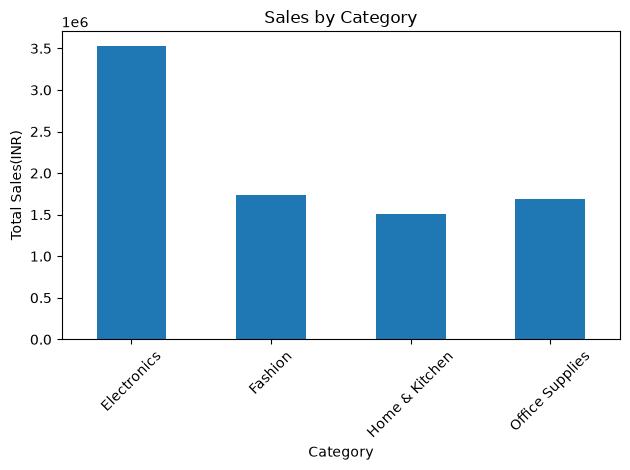

In [10]:
import matplotlib.pyplot as plt
Category_sales =df.groupby("Category")["Revenue_INR"].sum()
Category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales(INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
region_sales =df.groupby("Region")["Revenue_INR"].sum()

print(region_sales.sort_values(ascending=False))

Region
West       2274373.37
South      1784546.64
North      1538117.74
East       1469194.18
Central    1400859.18
Name: Revenue_INR, dtype: float64


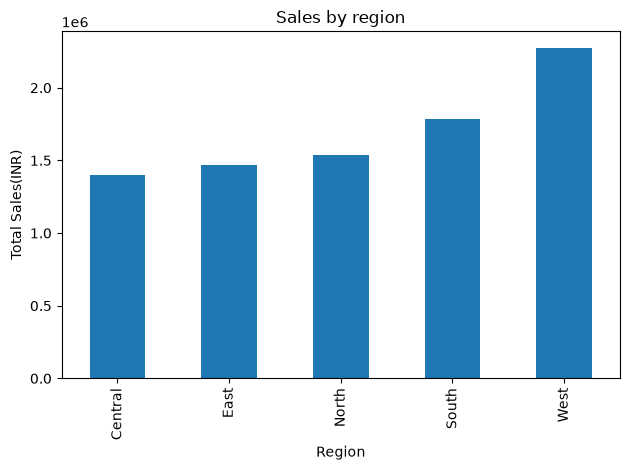

In [15]:
region_sales =df.groupby("Region")["Revenue_INR"].sum()
region_sales.plot(kind="bar")
plt.title("Sales by region")
plt.xlabel("Region")
plt.ylabel("Total Sales(INR)")
plt.tight_layout()
plt.show()

In [28]:
df["OrderDate"]=pd.to_datetime(df["OrderDate"])

monthly_sales=df.groupby(
    df["OrderDate"].dt.month
)["Revenue_INR"].sum()

print(monthly_sales)

OrderDate
1     791715.96
2     682534.87
3     698530.81
4     751436.63
5     719226.41
6     597725.30
7     869294.53
8     642423.78
9     644983.79
10    719985.64
11    657804.26
12    691429.13
Name: Revenue_INR, dtype: float64


AttributeError: module 'matplotlib.pyplot' has no attribute 'ylabl'

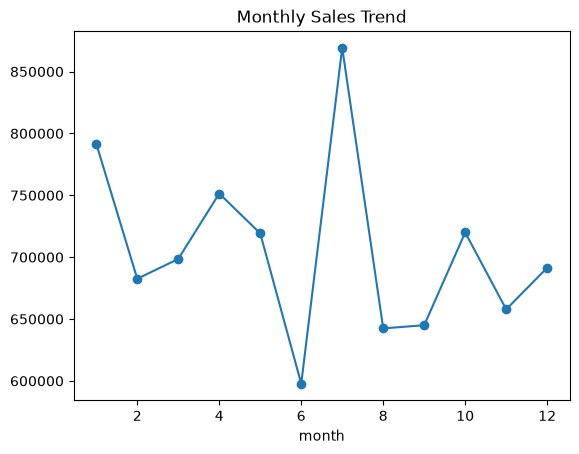

In [34]:
monthly_sales.plot(kind="line",
marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("month")
plt.ylabl("total Sales (INR)")
plt.grid(True)
plt.tight_layout()
plt.show()



In [36]:
product_profit=df.groupby("Product")["Profit_INR"].sum()

top_5_products=product_profit.sort_values(
    ascending=False).head(5)
print(top_5_products)

Product
Monitor          459353.78
Office Chair     284748.45
Jacket           232975.22
Headphones       160594.22
Mixer Grinder    157804.35
Name: Profit_INR, dtype: float64
